# IBM Telco Customer Churn — Supervised Learning
## Take-Home Group Assignment 1 · Modules 1–5

**Group:** Group 4  
**Date:** November 5, 2026

| Name |
| --- |
| Fabio Augusto De Oliveira Dutra |
| Gumashtha Devangiri Pandukabhaya Punchi Wedikkarage Don |
| Jose Vidal Asencio Santos |
| Mehrthur Luís Lemos da Silva |

We compare baseline and optimized Logistic Regression and Decision Tree classifiers. The reviewed feature set contains 20 predictors. ZIP Code is categorical; constants and repeated geographic fields are excluded.

**Reproduction:** keep `Dataset_Churn.xlsx` beside this notebook, install `requirements.txt`, and run all cells in order. The final cell exports the fitted CV-selected pipeline for the local API. The current cells were executed in a fresh Python process.

**Evaluation limitation:** the same test split was examined in earlier versions. The revised preprocessing was chosen for data meaning and redundancy, not to maximize test scores. Hyperparameter search uses training-only cross-validation, but these revised test results are not a new untouched validation. Further development needs new independent data or nested validation.

## 1. Problem definition — 10 marks

**Domain:** telecommunications customer retention.  
**Business problem:** help the retention team identify customers likely to leave and prioritize contact.  
**Prediction objective:** binary classification of recorded churn outcomes.  
**Target:** `Churn Value`, with churn = 1 and no churn = 0.  
**Predictors:** ZIP Code; Gender; Senior Citizen; Partner; Dependents; Tenure Months; Phone Service; Multiple Lines; Internet Service; Online Security; Online Backup; Device Protection; Tech Support; Streaming TV; Streaming Movies; Contract; Paperless Billing; Payment Method; Monthly Charges; Total Charges.

Historical labeled examples make supervised learning suitable. The intended operational use would score active customers before a retention decision. The file does not establish a future prediction horizon or verify the timing of every input, so production use requires a data-availability review.

A false negative misses a churner; a false positive may waste an offer or contact. Financial costs are unknown, so churn F1 balances precision and recall. Predictive associations do not prove that a retention action prevents churn. Dataset source: [1].

In [1]:
# Install dependencies in the notebook environment if necessary:
# %pip install pandas numpy matplotlib seaborn scikit-learn openpyxl
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score,
)
import sklearn

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
print("pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)

pandas: 3.0.6 | scikit-learn: 1.9.1


## 2. Load and inspect the dataset

Source: [IBM Telco Customer Churn Dataset on Kaggle](https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset).

Set the exact downloaded filename. The loader supports CSV and Excel; inspect the sheet names if the workbook contains multiple sheets. Column names and label values are validated rather than assuming a particular dataset variant.

In [2]:
# openpyxl is already installed.
# %pip install openpyxl

In [3]:
DATA_PATH = Path("Dataset_Churn.xlsx")
EXCEL_SHEET = 0

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}. Download the dataset, "
        "place it beside this notebook, and update DATA_PATH."
    )
if DATA_PATH.suffix.lower() == ".csv":
    raw = pd.read_csv(DATA_PATH)
elif DATA_PATH.suffix.lower() in {".xlsx", ".xls"}:
    raw = pd.read_excel(DATA_PATH, sheet_name=EXCEL_SHEET)
else:
    raise ValueError("Use a CSV or Excel file; extract downloaded ZIP archives first.")
raw.columns = raw.columns.str.strip()
if raw.columns.duplicated().any():
    raise ValueError("Duplicate column names found; inspect the source file.")
print("Raw dimensions:", raw.shape)
display(raw.head())
raw.info()
display(raw.describe(include="all").T)
display(raw.isna().sum().sort_values(ascending=False).to_frame("Missing"))
print("Exact duplicate rows:", raw.duplicated().sum())

Raw dimensions: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,7043,7043,3668-QPYBK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Count,7043.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
Country,7043,1,United States,7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,7043,1,California,7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,7043,1129,Los Angeles,305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zip Code,7043.0,NaN,NaN,NaN,93521.964646,1865.794555,90001.0,92102.0,93552.0,95351.0,96161.0
Lat Long,7043,1652,"33.964131, -118.272783",5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latitude,7043.0,NaN,NaN,NaN,36.282441,2.455723,32.555828,34.030915,36.391777,38.224869,41.962127
Longitude,7043.0,NaN,NaN,NaN,-119.79888,2.157889,-124.301372,-121.815412,-119.730885,-118.043237,-114.192901
Gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Missing
Churn Reason,5174
Online Security,0
CLTV,0
Churn Score,0
Churn Value,0
Churn Label,0
Total Charges,0
Monthly Charges,0
Payment Method,0
Paperless Billing,0


Exact duplicate rows: 0


### Target, schema, and leakage review

`Churn Value` is the target. `Churn Label` gives the same outcome in text. CustomerID, Count, Churn Label, Churn Score and Churn Reason are excluded. CLTV is excluded because its calculation and availability before churn were not confirmed; this does not prove that CLTV contains leakage.

Country and State are constant in this file. City, Lat Long, Latitude and Longitude are removed to avoid retaining several encodings of location. ZIP Code is kept as the single geographic field and converted to a five-character string before one-hot encoding. This is a schema decision rather than a feature ranking based on test results. ZIP Code still has many categories, which is a limitation to validate.

Whitespace-only entries become missing values. Billing fields are converted to numbers. Exact duplicates are checked before splitting; repeated customer IDs trigger an error and further investigation. The remaining fields represent plausible customer and account inputs, but their production-time availability is an assumption to verify. Pipeline practice follows [2].

In [4]:
def column_key(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

TARGET_COLUMN = "Churn Value"  # Set explicitly if automatic detection is ambiguous.
target_keys = {"churn", "churnlabel", "churnvalue"}
candidates = [c for c in raw.columns if column_key(c) in target_keys]
if TARGET_COLUMN is None:
    if len(candidates) != 1:
        raise ValueError(f"Set TARGET_COLUMN explicitly. Candidate target fields: {candidates}")
    TARGET_COLUMN = candidates[0]
if TARGET_COLUMN not in raw.columns:
    raise ValueError(f"Target not found: {TARGET_COLUMN}")

# Extend after reading the dataset dictionary and defining the prediction time.
# Keep ZIP Code as the single geographic representation. Remove constant
# fields and repeated location encodings based on schema, not test scores.
EXTRA_EXCLUDE = ["CLTV", "Country", "State", "City", "Lat Long", "Latitude", "Longitude"]
excluded_keys = {
    "customerid", "customerstatus", "churn", "churnlabel", "churnvalue",
    "churnscore", "churncategory", "churnreason", "count",
}
excluded = [c for c in raw.columns
            if c != TARGET_COLUMN and (column_key(c) in excluded_keys or c in EXTRA_EXCLUDE)]

clean = raw.copy()
text_columns = clean.select_dtypes(include=["object", "string"]).columns
for col in text_columns:
    clean[col] = clean[col].map(lambda value: value.strip() if isinstance(value, str) else value)
clean = clean.replace(r"^\s*$", np.nan, regex=True)
for col in clean.columns:
    if column_key(col) in {"totalcharges", "monthlycharges", "monthlycharge"}:
        clean[col] = pd.to_numeric(clean[col], errors="raise")

before = len(clean)
clean = clean.drop_duplicates().copy()
print("Exact duplicate rows removed:", before - len(clean))
if clean[TARGET_COLUMN].isna().any():
    raise ValueError("Missing target labels found. Investigate before proceeding.")
label_map = {"yes": 1, "no": 0, "1": 1, "0": 0, "1.0": 1, "0.0": 0}
y = clean[TARGET_COLUMN].astype(str).str.strip().str.lower().map(label_map)
if y.isna().any() or y.nunique() != 2:
    raise ValueError("Expected two target classes encoded as Yes/No or 1/0. Inspect target values.")
y = y.astype(int).rename("Churn")
X = clean.drop(columns=[TARGET_COLUMN] + excluded)
# ZIP codes identify areas; numeric distances between codes have no meaning.
for col in X.columns:
    if column_key(col) == "zipcode":
        codes = pd.to_numeric(X[col], errors="raise")
        if ((codes.dropna() % 1) != 0).any():
            raise ValueError("ZIP Code must contain integer codes or missing values.")
        X[col] = codes.map(lambda value: f"{int(value):05d}" if pd.notna(value) else np.nan)
if X.empty:
    raise ValueError("No predictors remain.")
print("Target:", TARGET_COLUMN)
print("Excluded columns:", excluded)
display(pd.DataFrame({"dtype": X.dtypes, "unique": X.nunique(), "missing": X.isna().sum()}))

id_cols = [c for c in clean.columns if column_key(c) == "customerid"]
for col in id_cols:
    if clean[col].duplicated().any():
        raise ValueError("Repeated customer IDs found. Investigate and use a customer-level split if needed.")

Exact duplicate rows removed: 0
Target: Churn Value
Excluded columns: ['CustomerID', 'Count', 'Country', 'State', 'City', 'Lat Long', 'Latitude', 'Longitude', 'Churn Label', 'Churn Score', 'CLTV', 'Churn Reason']


,dtype,unique,missing
Zip Code,str,1652,0
Gender,str,2,0
Senior Citizen,str,2,0
Partner,str,2,0
Dependents,str,2,0
Tenure Months,int64,73,0
Phone Service,str,2,0
Multiple Lines,str,3,0
Internet Service,str,3,0
Online Security,str,3,0


### Protect the final test set

Use the same stratified 80/20 split for all four models. Detailed exploratory analysis below uses training data only. Learned preprocessing is fitted separately inside each cross-validation training fold.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Training dimensions:", X_train.shape)
print("Test dimensions:", X_test.shape)
eda = X_train.copy()
eda["Churn"] = y_train
class_summary = y_train.value_counts().sort_index().to_frame("Count")
class_summary["Proportion"] = y_train.value_counts(normalize=True).sort_index()
display(class_summary)
display(X_train.describe(include="all").T)
display(X_train.isna().sum().sort_values(ascending=False).to_frame("Training missing"))

Training dimensions: (5634, 20)
Test dimensions: (1409, 20)


,Count,Proportion
Churn,,
0,4139,0.734647
1,1495,0.265353


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Zip Code,5634,1650,91302,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,5634,2,Male,2833,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Senior Citizen,5634,2,No,4714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Partner,5634,2,No,2905,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,5634,2,No,4333,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tenure Months,5634.0,NaN,NaN,NaN,32.485091,24.568744,0.0,9.0,29.0,55.0,72.0
Phone Service,5634,2,Yes,5075,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Multiple Lines,5634,3,No,2685,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Internet Service,5634,3,Fiber optic,2483,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Online Security,5634,3,No,2797,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Training missing
Total Charges,8
Gender,0
Monthly Charges,0
Payment Method,0
Paperless Billing,0
Contract,0
Streaming Movies,0
Streaming TV,0
Tech Support,0
Device Protection,0


## 3. Exploratory data analysis — 15 marks

The figures examine class distribution and associations with churn. They use training observations only. Review the plots and explain their implications; class balance alone does not determine the best metric.

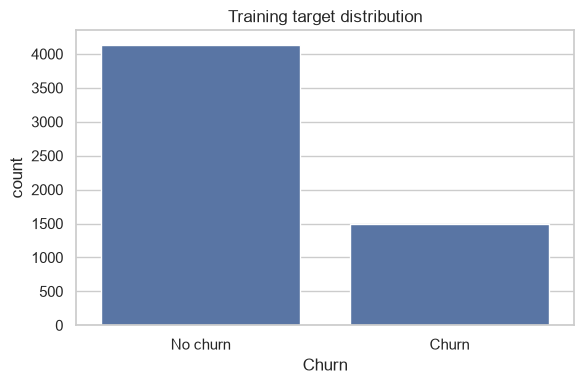

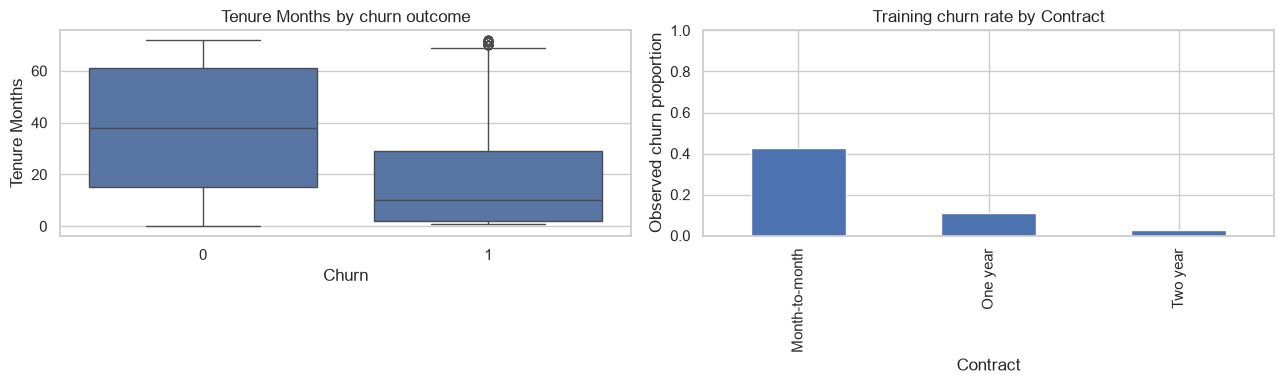

,Churn rate,Customers
Contract,,
Month-to-month,0.427466,3102
One year,0.110827,1173
Two year,0.028698,1359


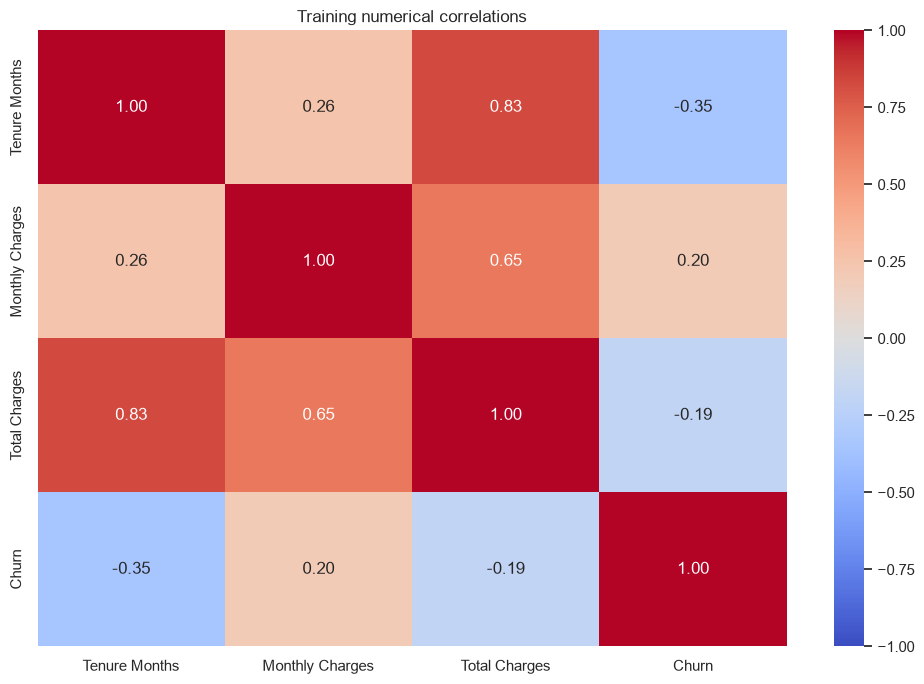

,Correlation with churn
Tenure Months,-0.345593
Total Charges,-0.194814
Monthly Charges,0.198040


,Tenure Months,Monthly Charges,Total Charges
Churn,,,
No churn,38.0,64.40,1691.9
Churn,10.0,79.95,740.3


,Outside 1.5 IQR fences
Tenure Months,0
Monthly Charges,0
Total Charges,0


Tenure for missing Total Charges:


Tenure Months
0    11
Name: count, dtype: int64

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=eda, x="Churn", ax=ax)
ax.set_xticks([0, 1], ["No churn", "Churn"])
ax.set_title("Training target distribution")
plt.tight_layout()
plt.show()

numeric_columns = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_columns = [c for c in X_train.columns if c not in numeric_columns]
# Prefer interpretable fields, with fallbacks for other dataset variants.
by_key = {column_key(c): c for c in X_train.columns}
num_plot = next((by_key[k] for k in ["tenure", "tenuremonths", "tenureinmonths", "monthlycharges", "monthlycharge"]
                 if k in by_key and by_key[k] in numeric_columns), None)
if num_plot is None and numeric_columns:
    num_plot = numeric_columns[0]
cat_plot = next((by_key[k] for k in ["contract", "internetservice", "paymentmethod"]
                 if k in by_key and by_key[k] in categorical_columns), None)
if cat_plot is None:
    cat_plot = next((c for c in categorical_columns if X_train[c].nunique() <= 15), None)
if num_plot is None or cat_plot is None:
    raise ValueError("Select suitable numerical and categorical fields for the required EDA plots.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=eda, x="Churn", y=num_plot, ax=axes[0])
axes[0].set_title(f"{num_plot} by churn outcome")
rates = eda.groupby(cat_plot, observed=True)["Churn"].agg(["mean", "size"])
rates["mean"].plot.bar(ax=axes[1])
axes[1].set_ylabel("Observed churn proportion")
axes[1].set_ylim(0, 1)
axes[1].set_title(f"Training churn rate by {cat_plot}")
plt.tight_layout()
plt.show()
display(rates.rename(columns={"mean": "Churn rate", "size": "Customers"}))

if numeric_columns:
    corr = eda[numeric_columns + ["Churn"]].corr()
    plt.figure(figsize=(10, 7))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
    plt.title("Training numerical correlations")
    plt.tight_layout()
    plt.show()
# Numerical evidence for the written EDA, using training data only.
display(corr["Churn"].drop("Churn").sort_values().to_frame("Correlation with churn"))
eda_by_churn = eda.groupby("Churn")[numeric_columns].median()
display(eda_by_churn.rename(index={0: "No churn", 1: "Churn"}))
q1 = X_train[numeric_columns].quantile(0.25)
q3 = X_train[numeric_columns].quantile(0.75)
iqr = q3 - q1
outlier_counts = ((X_train[numeric_columns] < q1 - 1.5 * iqr) |
                  (X_train[numeric_columns] > q3 + 1.5 * iqr)).sum()
display(outlier_counts.to_frame("Outside 1.5 IQR fences"))
print("Tenure for missing Total Charges:")
display(clean.loc[clean["Total Charges"].isna(), "Tenure Months"].value_counts())


### EDA interpretation

**Dimensions and types.** The original file has 7,043 customers and 33 columns. We exclude 12 fields and use Churn Value as the target, leaving 20 predictors: 3 numerical and 17 categorical. The training set has 5,634 customers and the test set has 1,409. ZIP Code is categorical, and Total Charges was converted from text to numeric.

**Missing values.** Total Charges has 11 missing values in the full file, including 8 in training. All 11 affected records have zero tenure. This suggests that these customers may not yet have accumulated charges, although the file does not confirm the cause. We use the training-fold median rather than assume a true charge of zero. Churn Reason is missing for 5,174 customers, matching the number of non-churners; it is excluded because it describes an outcome. No exact duplicate records were found.

**Class balance.** Training contains 4,139 non-churners (73.46%) and 1,495 churners (26.54%). A classifier that always predicts no churn would have 73.46% training accuracy but zero churn recall. This explains why accuracy alone is insufficient.

**Relationships supported by the figures and tables:**

1. Churners have median tenure of 10 months, compared with 38 months for non-churners. The tenure–churn correlation is −0.3456. Shorter customer relationships are associated with churn in this sample.
2. Month-to-month contracts have 42.75% churn (3,102 training customers), compared with 11.08% for one-year contracts (1,173) and 2.87% for two-year contracts (1,359). Contract type may be useful for classification.
3. Churners have median monthly charges of 79.95, compared with 64.40 for non-churners. Monthly charges have correlation 0.1980 with churn. Higher monthly charges are associated with more churn, but the relationship is modest.
4. Median total charges are lower for churners (740.30) than non-churners (1,691.90); correlation with churn is −0.1948. Total charges reflect both billing and duration, so the result should not be interpreted as a causal effect of paying more.

**Outliers.** None of the three numerical predictors falls outside its training-data 1.5-IQR fences. This rule does not prove the data is error-free. Total Charges is right-skewed: its mean is 2,302.60 and median is 1,398.13. High values may be valid for longer-term customers, so no numerical rows were removed.

**Implications.** Tenure, contract and charges deserve attention in interpretation. The evidence shows associations, not causes. All detailed EDA and numerical summaries above use training data; basic file-quality checks describe the full source.

## 4. Data preprocessing — 15 marks

The same transformations and observations are used for all four models.

| Decision | Implementation and reason |
| --- | --- |
| Missing numeric values | Median fitted on each training fold; retains customers and is less sensitive to skew than the mean. |
| Missing categories | Most-frequent category fitted on each training fold. |
| ZIP Code | Five-character string and one-hot encoding; numeric distance between postal codes has no business meaning. |
| Other categories | One-hot encoding with unseen categories ignored; avoids imposing an artificial order. |
| Numerical scale | StandardScaler for the three numerical inputs; supports Logistic Regression and keeps preprocessing common. Trees do not require scaling. |
| Constant fields | Remove Country, State and Count; they do not vary in this file. |
| Repeated location fields | Remove City, Lat Long, Latitude and Longitude; retain ZIP Code as one geographic representation. |
| Identifier and outcomes | Remove CustomerID, Churn Label, Churn Score and Churn Reason. |
| CLTV | Exclude because calculation and availability before churn are unconfirmed; this is precautionary, not proof of leakage. |
| Duplicates | Check before splitting; none were found, so no rows were removed. |
| Split | Stratified 80/20 split with random_state=42; preserves class proportions and keeps the comparison consistent. |

All learned transformations are inside Pipeline and ColumnTransformer so each CV fold learns its own imputation, encoding and scaling [2]. No resampling is performed; balanced class weights are considered during Logistic Regression tuning. The shared preprocessing satisfies the assignment's fair-comparison requirement.

In [7]:
def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ])

def make_model(estimator):
    return Pipeline([("preprocessor", make_preprocessor()), ("model", estimator)])

all_missing = X_train.columns[X_train.isna().all()].tolist()
if all_missing:
    raise ValueError(f"Entirely missing training columns require a decision: {all_missing}")

## 5. Model development and optimization — 25 marks

**Logistic Regression:** a regularized linear classification reference with coefficients that can be inspected [3].  
**Decision Tree:** learns nonlinear rules and interactions, but an unrestricted tree may overfit [4].

Baseline means the initial untuned version of each required algorithm. Both use random_state=42 where applicable. Logistic Regression uses max_iter=3000; the tree baseline is unrestricted.

**Selection metric:** F1 for churn balances precision and recall when financial error costs are not known. We do not change this objective after looking at the revised test. Five shuffled stratified folds are shared across candidates. GridSearchCV evaluates the grid on training data and refits the best candidate on the full training set [5]. All preprocessing is inside the searched pipeline [2]. The default class decision is used; no threshold is tuned on the test set.

In [8]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
SELECTION_METRIC = "f1"
if y_train.value_counts().min() < CV.n_splits:
    raise ValueError("Not enough minority-class observations for five-fold stratified CV.")

baseline_models = {
    "Logistic Regression (Baseline)": make_model(
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
    "Decision Tree (Baseline)": make_model(
        DecisionTreeClassifier(random_state=RANDOM_STATE)),
}
cv_rows = []
for name, model in baseline_models.items():
    scores = cross_validate(model, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    row = {"Model": name}
    for metric in SCORING:
        row[f"CV {metric} mean"] = scores[f"test_{metric}"].mean()
        row[f"CV {metric} std"] = scores[f"test_{metric}"].std()
    cv_rows.append(row)
    model.fit(X_train, y_train)
display(pd.DataFrame(cv_rows).set_index("Model").round(4))

,CV accuracy mean,CV accuracy std,CV precision mean,CV precision std,CV recall mean,CV recall std,CV f1 mean,CV f1 std,CV roc_auc mean,CV roc_auc std
Model,,,,,,,,,,
Logistic Regression (Baseline),0.8072,0.0095,0.6592,0.0220,0.5672,0.0325,0.6093,0.023,0.8488,0.0132
Decision Tree (Baseline),0.7657,0.0118,0.5658,0.0275,0.5084,0.0389,0.5347,0.027,0.6835,0.0175


In [9]:
search_specs = {
    "Optimized Logistic Regression": (
        make_model(LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
        {"model__C": [0.01, 0.1, 1.0, 10.0],
         "model__class_weight": [None, "balanced"]},
    ),
    "Optimized Decision Tree": (
        make_model(DecisionTreeClassifier(random_state=RANDOM_STATE)),
        {"model__max_depth": [3, 5, 8, None],
         "model__min_samples_leaf": [1, 5, 15],
         "model__min_samples_split": [2, 10],
         "model__criterion": ["gini", "entropy"]},
    ),
}
searches = {}
for name, (pipeline, param_grid) in search_specs.items():
    search = GridSearchCV(
        pipeline, param_grid, cv=CV, scoring=SCORING,
        refit=SELECTION_METRIC, n_jobs=-1, error_score="raise",
    )
    search.fit(X_train, y_train)
    searches[name] = search
    print(name)
    print("Best parameters:", search.best_params_)
    print("Best cross-validation F1:", round(search.best_score_, 4))
    results = pd.DataFrame(search.cv_results_)
    display(results[["params", "mean_test_f1", "std_test_f1", "mean_test_recall",
                     "mean_test_precision"]].sort_values("mean_test_f1", ascending=False).head())

models = {**baseline_models, **{name: search.best_estimator_ for name, search in searches.items()}}
selection_rows = [{"Model": row["Model"], "CV F1": row["CV f1 mean"]} for row in cv_rows]
selection_rows += [{"Model": name, "CV F1": search.best_score_} for name, search in searches.items()]
selection_table = pd.DataFrame(selection_rows).set_index("Model").sort_values("CV F1", ascending=False)
recommended_name = selection_table.index[0]
display(selection_table)
print("Model selected using training CV only:", recommended_name)

Optimized Logistic Regression
Best parameters: {'model__C': 0.1, 'model__class_weight': 'balanced'}
Best cross-validation F1: 0.6432


,params,mean_test_f1,std_test_f1,mean_test_recall,mean_test_precision
3,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.643161,0.022411,0.804682,0.535986
1,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.637458,0.021812,0.793311,0.533076
5,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.629339,0.024537,0.765886,0.534316
2,"{'model__C': 0.1, 'model__class_weight': None}",0.616030,0.032839,0.571906,0.668946
4,"{'model__C': 1.0, 'model__class_weight': None}",0.609298,0.022970,0.567224,0.659203


Optimized Decision Tree
Best parameters: {'model__criterion': 'entropy', 'model__max_depth': 5, 'model__min_samples_leaf': 15, 'model__min_samples_split': 2}
Best cross-validation F1: 0.6128


,params,mean_test_f1,std_test_f1,mean_test_recall,mean_test_precision
35,"{'model__criterion': 'entropy', 'model__max_de...",0.612828,0.028970,0.616722,0.615253
34,"{'model__criterion': 'entropy', 'model__max_de...",0.612828,0.028970,0.616722,0.615253
33,"{'model__criterion': 'entropy', 'model__max_de...",0.612416,0.028457,0.616054,0.615027
32,"{'model__criterion': 'entropy', 'model__max_de...",0.612416,0.028457,0.616054,0.615027
31,"{'model__criterion': 'entropy', 'model__max_de...",0.611231,0.028001,0.614716,0.614176


,CV F1
Model,
Optimized Logistic Regression,0.643161
Optimized Decision Tree,0.612828
Logistic Regression (Baseline),0.609298
Decision Tree (Baseline),0.534724


Model selected using training CV only: Optimized Logistic Regression


### Optimization interpretation

| Model | Selected settings | Mean CV F1 | Fold standard deviation |
| --- | --- | ---: | ---: |
| Logistic Regression baseline | C=1, no weighting | 0.6093 | 0.0230 |
| Decision Tree baseline | Default unrestricted tree | 0.5347 | 0.0270 |
| Optimized Logistic Regression | C=0.1, class_weight=balanced | 0.6432 | 0.0224 |
| Optimized Decision Tree | entropy, max_depth=5, min_samples_leaf=15, min_samples_split=2 | 0.6128 | 0.0290 |

**Logistic Regression.** The grid tests 8 combinations: four C values (0.01, 0.1, 1, 10) with class_weight set to None or balanced. Smaller C applies stronger regularization. Balanced weighting increases the minority churn class's contribution [3]. CV F1 rises from 0.6093 to 0.6432.

**Decision Tree.** The grid tests 48 combinations of depth (3, 5, 8, None), minimum leaf size (1, 5, 15), minimum split size (2, 10), and Gini versus entropy. Depth and leaf size control complexity; the criterion measures class impurity for splits [4]. CV F1 rises from 0.5347 to 0.6128.

The optimized Logistic Regression has the highest CV F1, so it is selected before the revised test evaluation. Fold standard deviations describe variation, not confidence intervals. The best grid-search score may be optimistic because it also selects hyperparameters. No claim of statistical significance is made.

## 6. Revised test evaluation and comparison — 20 marks

Evaluate the four fixed models on the same 1,409 test customers. The displayed test has already been examined in earlier project versions; it is a revised comparison, not a new untouched validation. Hyperparameters and the model recommendation are selected using training-only CV. Do not use these test scores to restart tuning. New independent data is needed for the next final validation.


Logistic Regression (Baseline)
              precision    recall  f1-score   support

    No churn       0.85      0.88      0.87      1035
       Churn       0.64      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409


Decision Tree (Baseline)
              precision    recall  f1-score   support

    No churn       0.84      0.86      0.85      1035
       Churn       0.58      0.55      0.57       374

    accuracy                           0.78      1409
   macro avg       0.71      0.70      0.71      1409
weighted avg       0.77      0.78      0.77      1409


Optimized Logistic Regression
              precision    recall  f1-score   support

    No churn       0.90      0.74      0.81      1035
       Churn       0.52      0.76      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      

,Train Accuracy,Test Accuracy,Precision,Recall,F1-score,ROC-AUC,Accuracy Gap,Comments
Model,,,,,,,,
Logistic Regression (Baseline),0.8608,0.7984,0.6355,0.5642,0.5977,0.8439,0.0624,Untuned linear reference
Decision Tree (Baseline),1.0000,0.7750,0.5798,0.5535,0.5663,0.7043,0.2250,Unrestricted tree reference
Optimized Logistic Regression,0.7728,0.7480,0.5172,0.7647,0.6170,0.8487,0.0248,CV-tuned regularization and weighting
Optimized Decision Tree,0.8032,0.7913,0.6081,0.6016,0.6048,0.8354,0.0118,CV-tuned tree complexity


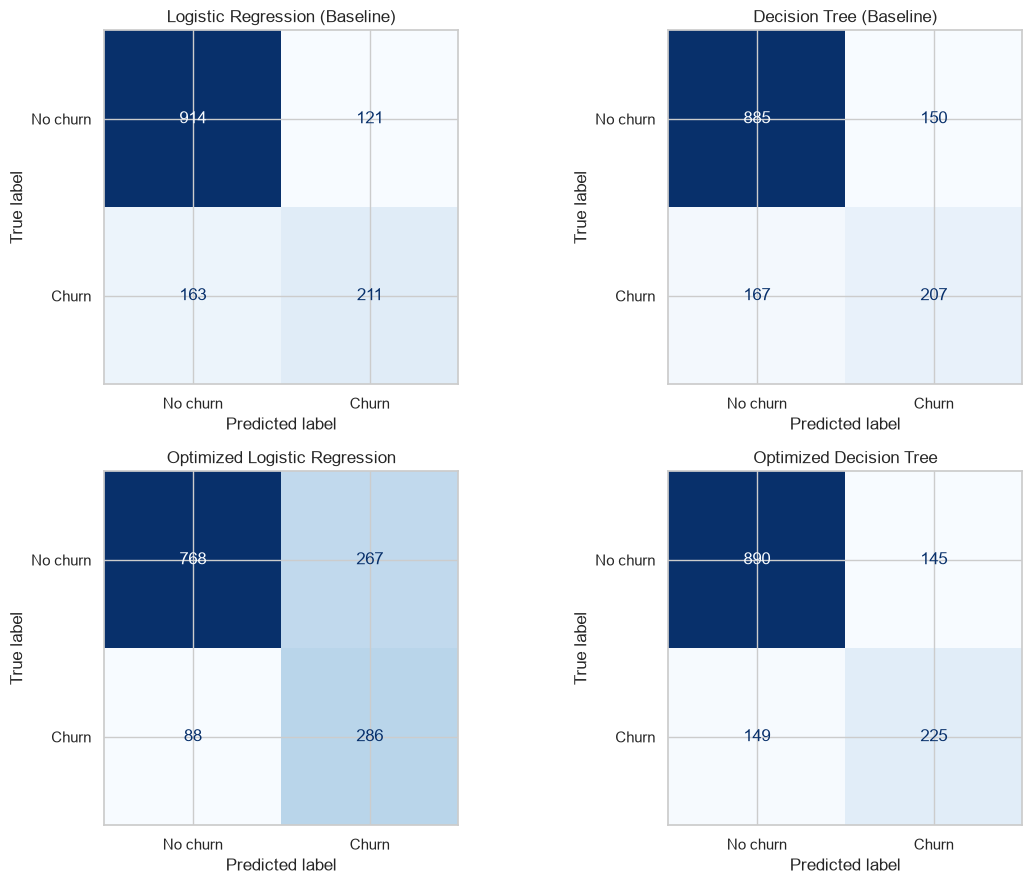

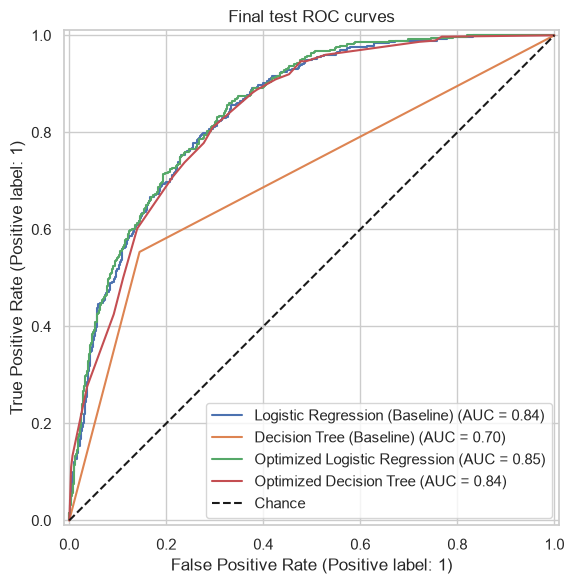

In [10]:
evaluation_rows = []
test_predictions = {}
for name, model in models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    test_predictions[name] = test_pred
    positive_index = list(model.classes_).index(1)
    test_prob = model.predict_proba(X_test)[:, positive_index]
    evaluation_rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred, zero_division=0),
        "Recall": recall_score(y_test, test_pred, zero_division=0),
        "F1-score": f1_score(y_test, test_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, test_prob),
    })
    print("\n" + name)
    print(classification_report(y_test, test_pred, labels=[0, 1],
                                target_names=["No churn", "Churn"], zero_division=0))
comparison = pd.DataFrame(evaluation_rows).set_index("Model")
comparison["Accuracy Gap"] = comparison["Train Accuracy"] - comparison["Test Accuracy"]
comparison["Comments"] = [
    "Untuned linear reference", "Unrestricted tree reference",
    "CV-tuned regularization and weighting", "CV-tuned tree complexity",
]
display(comparison.round(4))

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (name, prediction) in zip(axes.ravel(), test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, prediction, labels=[0, 1], display_labels=["No churn", "Churn"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
    RocCurveDisplay.from_predictions(y_test, probabilities, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Chance")
ax.set_title("Final test ROC curves")
ax.legend()
plt.tight_layout()
plt.show()

### Comparison discussion

**1. Best performance for our objective.** Optimized Logistic Regression has the best test F1 (0.6170) and the highest mean CV F1 (0.6432). This supports the CV-based recommendation for balanced churn detection. Logistic Regression baseline has the highest test accuracy (79.84%); highest accuracy and highest churn F1 identify different models.

**2. Generalization.** The optimized tree has the smallest accuracy gap: 80.32% in training and 79.13% in testing (1.18 percentage points). Optimized Logistic Regression has a 2.48-point gap: 77.28% versus 74.80%. The baseline tree has 100% training accuracy but 77.50% test accuracy, showing overfitting. A smaller accuracy gap alone does not establish the best churn detector.

**3. Effect of optimization.** Logistic Regression test F1 improves from 0.5977 to 0.6170 and recall from 0.5642 to 0.7647. Precision falls from 0.6355 to 0.5172, and accuracy falls from 79.84% to 74.80%. Tree F1 improves from 0.5663 to 0.6048, and accuracy improves from 77.50% to 79.13%. Both optimized models improve the selected F1 metric, with different trade-offs.

**4. Errors.** The test set has 374 churners and 1,035 non-churners.

| Model | Detected churners TP | Missed churners FN | Incorrect churn alerts FP | Correct non-churners TN |
| --- | ---: | ---: | ---: | ---: |
| Logistic Regression baseline | 211 | 163 | 121 | 914 |
| Decision Tree baseline | 207 | 167 | 150 | 885 |
| Optimized Logistic Regression | 286 | 88 | 267 | 768 |
| Optimized Decision Tree | 225 | 149 | 145 | 890 |

**5. Business trade-off.** Optimized Logistic Regression detects 286 of 374 churners, compared with 225 for the optimized tree: 61 extra churners detected, but 122 extra false alerts. Its precision is only 51.72%. This may be acceptable when missed churn is costly, but campaign costs must be measured. The tree offers higher precision and fewer unnecessary contacts.

**6. Recommendation.** We recommend optimized Logistic Regression for further validation under the stated F1 objective. It also has the highest ROC-AUC (0.8487). The small F1 advantage over the optimized tree (0.6170 versus 0.6048) is not proof of a statistically significant or profitable improvement. A final choice requires independent validation and explicit business costs.

## 7. Model interpretation

In optimized Logistic Regression, standardized tenure has coefficient −0.9949, and the month-to-month indicator has coefficient 0.6834. Holding other encoded inputs fixed, longer tenure lowers the fitted churn score and the month-to-month indicator raises it. Numerical inputs are standardized; category indicators are not, so coefficient magnitudes are not directly comparable. With all one-hot levels retained, the category coefficients should be read together rather than as isolated causal effects.

The optimized tree's largest impurity importance is month-to-month contract (0.5014), followed by tenure (0.1286), fiber-optic internet (0.1155), and the no-dependents indicator (0.1079). Contract and tenure are useful in both fitted models. Impurity importance may favor variables with many possible splits and can be affected by correlated inputs [4].

The diagram shows the first three levels of the optimized tree. Orange means No churn and blue means Churn. `value` gives [No churn, Churn] training counts; `samples` gives the number of training observations at a node. Numeric thresholds use standardized values, not raw months or charges. The complete tree has maximum depth 5; (...) indicates hidden branches. These are predictive associations, not evidence of causation.

,Coefficient
numeric__Tenure Months,-0.994858
categorical__Dependents_Yes,-0.775078
categorical__Dependents_No,0.765812
categorical__Contract_Month-to-month,0.683410
categorical__Contract_Two year,-0.607381
categorical__Zip Code_95567,0.353463
categorical__Internet Service_Fiber optic,0.351220
categorical__Zip Code_92382,0.313934
categorical__Internet Service_DSL,-0.288233
categorical__Zip Code_91773,0.285162


,Importance
categorical__Contract_Month-to-month,0.501368
numeric__Tenure Months,0.128563
categorical__Internet Service_Fiber optic,0.115505
categorical__Dependents_No,0.107936
numeric__Monthly Charges,0.056193
categorical__Payment Method_Electronic check,0.020270
numeric__Total Charges,0.018477
categorical__Online Security_No,0.015195
categorical__Tech Support_No,0.014993
categorical__Online Backup_No,0.007705


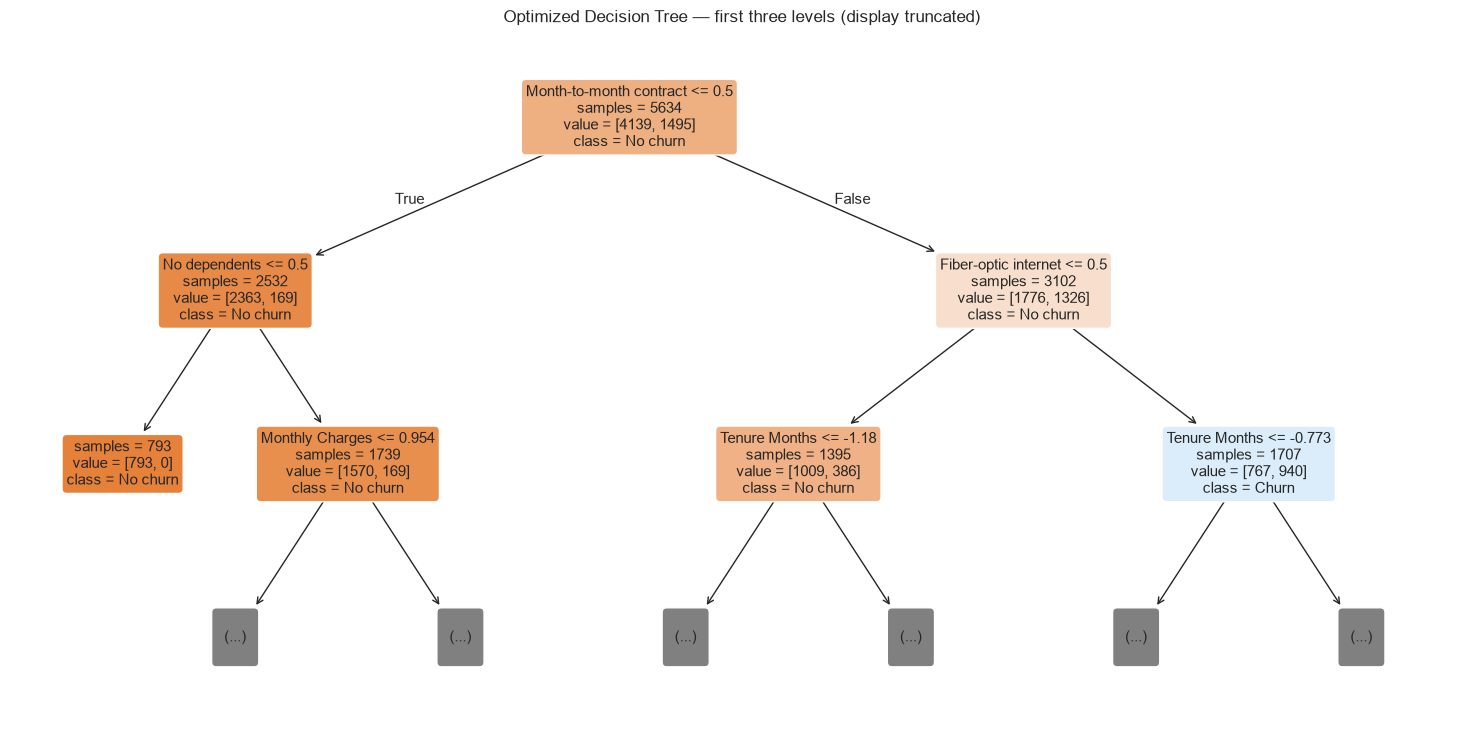

In [11]:
linear_pipeline = models["Optimized Logistic Regression"]
linear_features = linear_pipeline.named_steps["preprocessor"].get_feature_names_out()
coefficients = pd.Series(
    linear_pipeline.named_steps["model"].coef_[0], index=linear_features, name="Coefficient"
)
display(coefficients.loc[coefficients.abs().sort_values(ascending=False).head(15).index].to_frame())

tree_pipeline = models["Optimized Decision Tree"]
tree_features = tree_pipeline.named_steps["preprocessor"].get_feature_names_out()
importance = pd.Series(tree_pipeline.named_steps["model"].feature_importances_,
                       index=tree_features, name="Importance").sort_values(ascending=False)
display(importance.head(15).to_frame())
# Short display labels improve readability without changing the fitted inputs.
tree_display_names = [name.replace("categorical__", "").replace("numeric__", "")
                      .replace("Contract_Month-to-month", "Month-to-month contract")
                      .replace("Dependents_No", "No dependents")
                      .replace("Dependents_Yes", "Has dependents")
                      .replace("Internet Service_Fiber optic", "Fiber-optic internet")
                      for name in tree_features]
plt.figure(figsize=(15, 7.5))
plot_tree(tree_pipeline.named_steps["model"], feature_names=tree_display_names,
          class_names=["No churn", "Churn"], filled=True, max_depth=2, fontsize=11, rounded=True, impurity=False)
plt.title("Optimized Decision Tree — first three levels (display truncated)")
plt.tight_layout()
plt.show()

## 8. Discussion and conclusion — 15 marks

**Recommended candidate.** Optimized Logistic Regression has mean CV F1 0.6432, test F1 0.6170, recall 76.47%, and ROC-AUC 0.8487. It finds 286 churners and misses 88. Its coefficients and pipeline support inspection and repeatable inference.

**Main trade-off.** Precision is 51.72%, with 267 false alerts. The optimized tree has fewer false alerts (145), but misses more churners (149). The Logistic Regression baseline has the highest accuracy, 79.84%, but lower churn F1. F1 supports our choice; unknown contact and churn costs prevent a profitability claim.

**Optimization.** Both optimized models improve F1 over their corresponding baselines. Weighting and regularization favor better churn detection in Logistic Regression. Restricting tree complexity reduces the baseline tree's overfitting. Because multiple hyperparameters changed together, the experiment does not isolate each setting's causal contribution.

**Limitations.** Data is imbalanced and limited to California. ZIP Code has many categories; one-hot encoding can overfit local patterns and does not learn spatial distance. The data does not establish a future prediction period or production-time availability for every input. The same test split was examined before the feature review, so this revised test is not a new untouched evaluation. Fold variability and small score differences do not establish statistical significance.

**Possible improvements.** Evaluate the fixed workflow on new or later customers. On training validation data, test whether ZIP Code adds useful value, assess calibration, and choose thresholds using measured error costs. Further development should use nested validation or a new independent final test; do not keep tuning against this one.

**Lessons learned.** Perfect training accuracy can hide overfitting. Accuracy and F1 can rank models differently. Defining the meaning of each input, fitting preprocessing inside CV, and explaining errors are as important as obtaining a score.

**Before deployment.** Confirm the scoring time and input availability, compare performance across relevant customer groups, review fairness and privacy, measure campaign costs, and test whether retention actions improve outcomes. Plan monitoring for data changes and periodic retraining. The model artifact and local API demonstrate inference; they do not establish production readiness.

## Submission checklist

- [x] Group number, member names and preparation date completed.
- [x] Dataset source and schema documented; prediction-time assumptions and exclusions reviewed.
- [x] Problem, target and all retained predictors explained.
- [x] EDA includes more than three meaningful plots and numerical interpretations.
- [x] Shared preprocessing decisions justified, including categorical ZIP Code.
- [x] Four required models trained and compared.
- [x] Hyperparameters selected using training-only stratified cross-validation.
- [x] Training/test accuracy, classification reports, confusion matrices and comparison table included.
- [x] Conclusions supported by the revised experimental results.
- [x] All code cells executed in a fresh Python process; outputs inspected.
- [x] Notebook named Group4.ipynb.
- [x] Technical report updated and exported as Group4.pdf.

## References

[1] Yeanzc. (n.d.). *Telco customer churn: IBM dataset*. Kaggle. https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset

[2] scikit-learn developers. (n.d.). *Common pitfalls and recommended practices*. https://scikit-learn.org/stable/common_pitfalls.html

[3] scikit-learn developers. (n.d.). *LogisticRegression*. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

[4] scikit-learn developers. (n.d.). *DecisionTreeClassifier*. https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

[5] scikit-learn developers. (n.d.). *GridSearchCV*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

Online references accessed November 5, 2026. Course Modules 2–5 supplied the teaching examples for this workflow; the report's numerical results and figures come from this notebook's revised execution.

## 9. Export the model and use the local API

Export the CV-selected fitted pipeline, including preprocessing. This artifact uses the existing training fit; it is not refitted on test data. Run this cell again whenever the model or its inputs change. `models/churn_pipeline.joblib` is used by `api/server.py`; `models/example_request.json` contains a valid example request. The probability is a model estimate, not a guarantee of churn. This local API demonstrates inference and is not a production deployment.


In [12]:
import json
import platform
import joblib

export_dir = Path("models")
export_dir.mkdir(exist_ok=True)
selected_pipeline = models[recommended_name]
fields = []
for name in X_train.columns:
    field = {"name": name, "type": "number" if name in numeric_columns else "string"}
    if name not in numeric_columns:
        field["categories"] = sorted(X_train[name].dropna().astype(str).unique().tolist())
    fields.append(field)
example = json.loads(X_train.iloc[0].to_json())
artifact = {
    "artifact_version": 1,
    "model_name": recommended_name,
    "pipeline": selected_pipeline,
    "fields": fields,
    "example": example,
    "excluded_columns": excluded,
    "target": TARGET_COLUMN,
    "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                 "numpy": np.__version__, "scikit-learn": sklearn.__version__,
                 "joblib": joblib.__version__},
}
joblib.dump(artifact, export_dir / "churn_pipeline.joblib")
(export_dir / "schema.json").write_text(json.dumps(
    {k: v for k, v in artifact.items() if k != "pipeline"}, indent=2, ensure_ascii=False) + "\n")
(export_dir / "example_request.json").write_text(
    json.dumps({"customer": example}, indent=2, ensure_ascii=False) + "\n")
print("Exported:", artifact["model_name"])
print("Predictor count:", len(fields))
print("Start the API: python3 api/server.py")


Exported: Optimized Logistic Regression
Predictor count: 20
Start the API: python3 api/server.py
